# Consumer Complaint Classification (End-to-End Deep Learning & NLP)

**Objective:** Build an end-to-end NLP text classification pipeline that automatically predicts the complaint category from a customer's written complaint narrative.

### Stages Covered
1. **Setup & Dataset Import** (Kaggle / Google Colab compatible)
2. **Exploratory Data Analysis (EDA)**
3. **Text Preprocessing** (lowercasing, punctuation/numbers/special characters removal, stopwords removal, optional lemmatization)
4. **Class Distribution & Imbalance Handling** (`class_weight='balanced'` & weighted Cross-Entropy Loss)
5. **Tokenization, Sequence Padding & Embedding Layer**
6. **Training Custom Sequential Models from Scratch:** `SimpleRNN`, `LSTM`, `GRU`
7. **Fine-Tuning a HuggingFace Transformer:** `distilbert-base-uncased`
8. **Evaluation & 4-Model Comparison:** Accuracy, Precision, Recall, F1-score, Confusion Matrices
9. **Saving the Best Model & Inference on New Complaints**
10. **Interactive Gradio Web App Deployment**


## 0. Environment Setup & Dependencies


In [ ]:
# Install required packages (uncomment if running in Google Colab)
!pip -q install -U transformers datasets accelerate gradio kagglehub nltk scikit-learn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import json
import os
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import torch
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("TensorFlow version:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print("PyTorch version:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))


TensorFlow version: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch version: 2.14.1+cu130 | CUDA available: True
GPU Device: Tesla T4


## 1. Import & Explore the Dataset

Dataset: [Consumer Complaints Dataset for NLP (Kaggle)](https://www.kaggle.com/datasets/shashwatwork/consume-complaints-dataset-fo-nlp)


In [ ]:
# Automatically locate the dataset in Kaggle, local folder, or download via kagglehub
def load_complaints_dataset() -> pd.DataFrame:
    candidate_paths = [
        Path("/kaggle/input/consume-complaints-dataset-fo-nlp/complaints_processed.csv"),
        Path("complaints_processed.csv"),
        Path("data/complaints_processed.csv"),
    ]
    for path in candidate_paths:
        if path.exists():
            print(f"Loading dataset from: {path}")
            return pd.read_csv(path)

    print("Downloading dataset via kagglehub...")
    import kagglehub

    dataset_dir = Path(kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp"))
    csv_files = list(dataset_dir.glob("*.csv"))
    if not csv_files:
        raise FileNotFoundError(f"No CSV file found in {dataset_dir}")
    print(f"Loading dataset from: {csv_files[0]}")
    return pd.read_csv(csv_files[0])


df_raw = load_complaints_dataset()
print("Raw dataset shape:", df_raw.shape)
df_raw.head()


Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Loading dataset from: /kaggle/input/consume-complaints-dataset-fo-nlp/complaints_processed.csv
Raw dataset shape: (162421, 3)


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [ ]:
# Inspect columns, data types, missing values, and duplicates
print(df_raw.info())
print("\nMissing values per column:\n", df_raw.isnull().sum())

# Standardize column names (this dataset typically has 'Unnamed: 0', 'product', 'narrative')
df = df_raw.copy()
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Identify text and label columns automatically
TEXT_COL = "narrative" if "narrative" in df.columns else df.columns[-1]
LABEL_COL = "product" if "product" in df.columns else df.columns[0]
print(f"\nUsing TEXT_COL='{TEXT_COL}', LABEL_COL='{LABEL_COL}'")

# Drop missing & duplicate narratives
df = df[[TEXT_COL, LABEL_COL]].dropna()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL].str.len() > 0].drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)
print("Cleaned dataset shape:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB
None

Missing values per column:
 Unnamed: 0     0
product        0
narrative     10
dtype: int64

Using TEXT_COL='narrative', LABEL_COL='product'
Cleaned dataset shape: (124472, 2)


In [ ]:
# Optional: For faster experimentation on free Colab T4 GPU, you can cap the dataset size
# Set MAX_SAMPLES = None to use the entire dataset (~160k rows)
MAX_SAMPLES = 40000  # Recommended for fast Colab runs (~10-15 min total for all 4 models)

if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df, _ = train_test_split(
        df,
        train_size=MAX_SAMPLES,
        stratify=df[LABEL_COL],
        random_state=SEED,
    )
    df = df.reset_index(drop=True)
    print(f"Stratified sample created: {df.shape}")


Stratified sample created: (40000, 2)


## 2. Exploratory Data Analysis & Class Distribution


,Count,Percentage (%)
product,,
credit_reporting,18073,45.18
debt_collection,6767,16.92
mortgages_and_loans,6017,15.04
credit_card,4815,12.04
retail_banking,4328,10.82


Imbalance Ratio (max / min): 4.18x


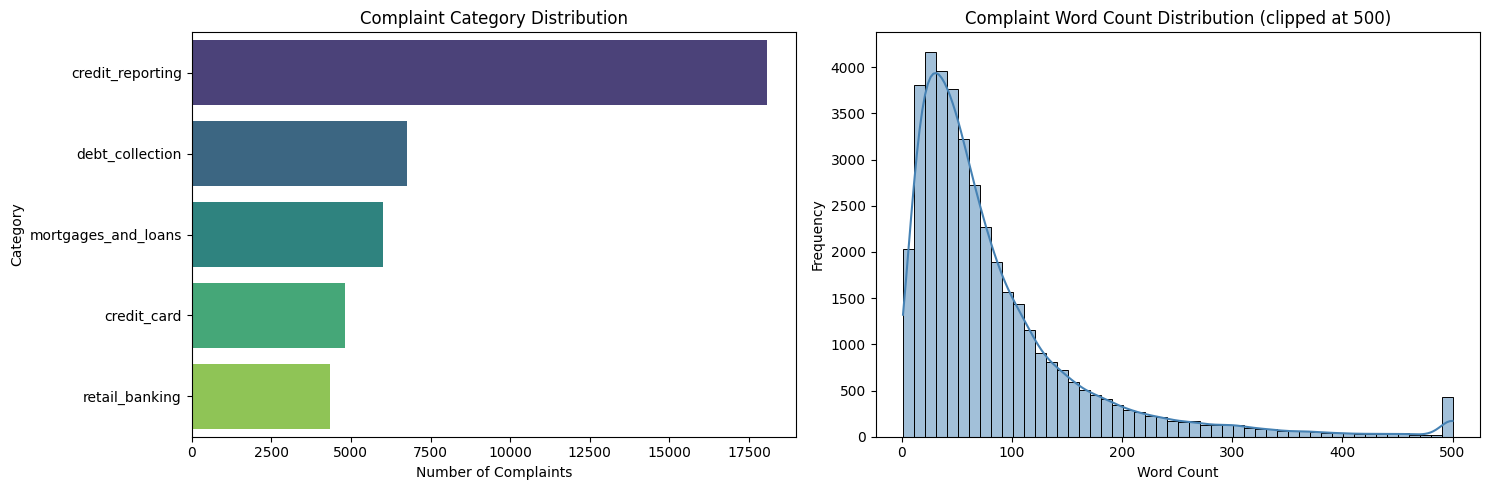

Word count percentiles: [ 57 104 181 257 507]


In [ ]:
class_counts = df[LABEL_COL].value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
dist_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})
display(dist_df)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance Ratio (max / min): {imbalance_ratio:.2f}x")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Class distribution
sns.barplot(x=class_counts.values, y=class_counts.index, palette="viridis", ax=axes[0])
axes[0].set_title("Complaint Category Distribution")
axes[0].set_xlabel("Number of Complaints")
axes[0].set_ylabel("Category")

# Narrative word count distribution
word_counts = df[TEXT_COL].str.split().str.len()
sns.histplot(word_counts.clip(upper=500), bins=50, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Complaint Word Count Distribution (clipped at 500)")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Word count percentiles:", np.percentile(word_counts, [50, 75, 90, 95, 99]).astype(int))


## 3. Text Preprocessing

For the custom sequential models (**SimpleRNN, LSTM, GRU**), we apply full text normalization:
- Lowercasing
- Removing punctuation, numbers, and special characters
- Removing English stop words
- Lemmatization (optional, controlled by `USE_LEMMATIZATION`)

For the **HuggingFace Transformer**, we preserve natural punctuation and casing/stopwords (light whitespace cleanup only), because pre-trained Transformers rely on contextual cues from stopwords and punctuation.


In [ ]:
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()
USE_LEMMATIZATION = True


def preprocess_text(text: str, use_lemmatization: bool = USE_LEMMATIZATION) -> str:
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)  # remove punctuation, numbers & special chars
    tokens = [w for w in text.split() if w not in STOP_WORDS and len(w) > 1]
    if use_lemmatization:
        tokens = [LEMMATIZER.lemmatize(w) for w in tokens]
    return " ".join(tokens)


df["clean_text"] = df[TEXT_COL].apply(preprocess_text)
df["raw_text"] = df[TEXT_COL].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

# Remove any rows that became empty after cleaning
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)

print("Sample Before vs After Preprocessing:")
for i in range(2):
    print(f"\n--- Example {i+1} ({df[LABEL_COL].iloc[i]}) ---")
    print("RAW  :", df["raw_text"].iloc[i][:220])
    print("CLEAN:", df["clean_text"].iloc[i][:220])


Sample Before vs After Preprocessing:

--- Example 1 (debt_collection) ---
RAW  : submitted final bill paid bill returned equipment received confirmation equipment received month later get another bill called asked bill told paid final bill understand gave u reason owe charge also happened neighbor mo
CLEAN: submitted final bill paid bill returned equipment received confirmation equipment received month later get another bill called asked bill told paid final bill understand gave reason owe charge also happened neighbor moth

--- Example 2 (mortgages_and_loans) ---
RAW  : applied refinance home loan estimate gave origination charge however loan closed change tell changed read loan fee complained forced sign cancelled loan take month loan
CLEAN: applied refinance home loan estimate gave origination charge however loan closed change tell changed read loan fee complained forced sign cancelled loan take month loan


## 4. Label Encoding, Stratified Train/Val/Test Split & Class Imbalance Handling


In [ ]:
label_encoder = LabelEncoder()
df["label_id"] = label_encoder.fit_transform(df[LABEL_COL])
NUM_CLASSES = len(label_encoder.classes_)
ID2LABEL = {i: label for i, label in enumerate(label_encoder.classes_)}
LABEL2ID = {label: i for i, label in enumerate(label_encoder.classes_)}

print("Classes:", ID2LABEL)

# Stratified 70% Train / 15% Validation / 15% Test split
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label_id"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label_id"], random_state=SEED
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# Compute balanced class weights to handle class imbalance
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label_id"].values,
)
CLASS_WEIGHT_DICT = {i: float(w) for i, w in enumerate(class_weights_arr)}
print("Balanced Class Weights:", {ID2LABEL[k]: round(v, 3) for k, v in CLASS_WEIGHT_DICT.items()})


Classes: {0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}
Train: 28000 | Val: 6000 | Test: 6000
Balanced Class Weights: {'credit_card': 1.662, 'credit_reporting': 0.443, 'debt_collection': 1.182, 'mortgages_and_loans': 1.33, 'retail_banking': 1.848}


## 5. Tokenization, Sequence Padding & Embedding Configuration


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_VOCAB_SIZE = 20000
MAX_LEN = 200
EMBEDDING_DIM = 128

keras_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(train_df["clean_text"])

X_train_pad = pad_sequences(
    keras_tokenizer.texts_to_sequences(train_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)
X_val_pad = pad_sequences(
    keras_tokenizer.texts_to_sequences(val_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)
X_test_pad = pad_sequences(
    keras_tokenizer.texts_to_sequences(test_df["clean_text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)

y_train = train_df["label_id"].values
y_val = val_df["label_id"].values
y_test = test_df["label_id"].values

print("Padded shapes:", X_train_pad.shape, X_val_pad.shape, X_test_pad.shape)


Padded shapes: (28000, 200) (6000, 200) (6000, 200)


## 6. Build & Train Custom Sequential Models (SimpleRNN, LSTM, GRU)


In [ ]:
from tensorflow.keras import layers, models, callbacks


def build_sequential_model(arch: str) -> tf.keras.Model:
    inputs = layers.Input(shape=(MAX_LEN,))
    x = layers.Embedding(input_dim=MAX_VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True)(inputs)
    x = layers.SpatialDropout1D(0.2)(x)

    if arch == "SimpleRNN":
        x = layers.SimpleRNN(64, dropout=0.2, recurrent_dropout=0.1)(x)
    elif arch == "LSTM":
        x = layers.Bidirectional(layers.LSTM(64, dropout=0.2))(x)
    elif arch == "GRU":
        x = layers.Bidirectional(layers.GRU(64, dropout=0.2))(x)
    else:
        raise ValueError(f"Unknown architecture: {arch}")

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name=arch)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


EPOCHS = 8
BATCH_SIZE = 128

keras_models = {}
keras_histories = {}
model_predictions = {}

for arch in ["SimpleRNN", "LSTM", "GRU"]:
    print(f"\n{'='*60}\nTraining {arch}...\n{'='*60}")
    model = build_sequential_model(arch)
    model.summary()

    cb_list = [
        callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5),
    ]

    history = model.fit(
        X_train_pad,
        y_train,
        validation_data=(X_val_pad, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHT_DICT,
        callbacks=cb_list,
        verbose=1,
    )

    keras_models[arch] = model
    keras_histories[arch] = history.history
    probs = model.predict(X_test_pad, batch_size=BATCH_SIZE, verbose=0)
    model_predictions[arch] = np.argmax(probs, axis=1)



Training SimpleRNN...


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 128)  │  2,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 200, 128)  │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │     12,352 │ spatial_dropout1… │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 5)         │        325 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,576,837 (9.83 MB)

 Trainable params: 2,576,837 (9.83 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 2,643,077 (10.08 MB)

 Trainable params: 2,643,077 (10.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.6946 - loss: 0.8433 - val_accuracy: 0.8070 - val_loss: 0.5647 - learning_rate: 0.0010
Epoch 2/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.8345 - loss: 0.4513 - val_accuracy: 0.8222 - val_loss: 0.5193 - learning_rate: 0.0010
Epoch 3/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8640 - loss: 0.3580 - val_accuracy: 0.8217 - val_loss: 0.5500 - learning_rate: 0.0010
Epoch 4/8
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.8911 - loss: 0.2727 - val_accuracy: 0.8187 - val_loss: 0.5689 - learning_rate: 5.0000e-04


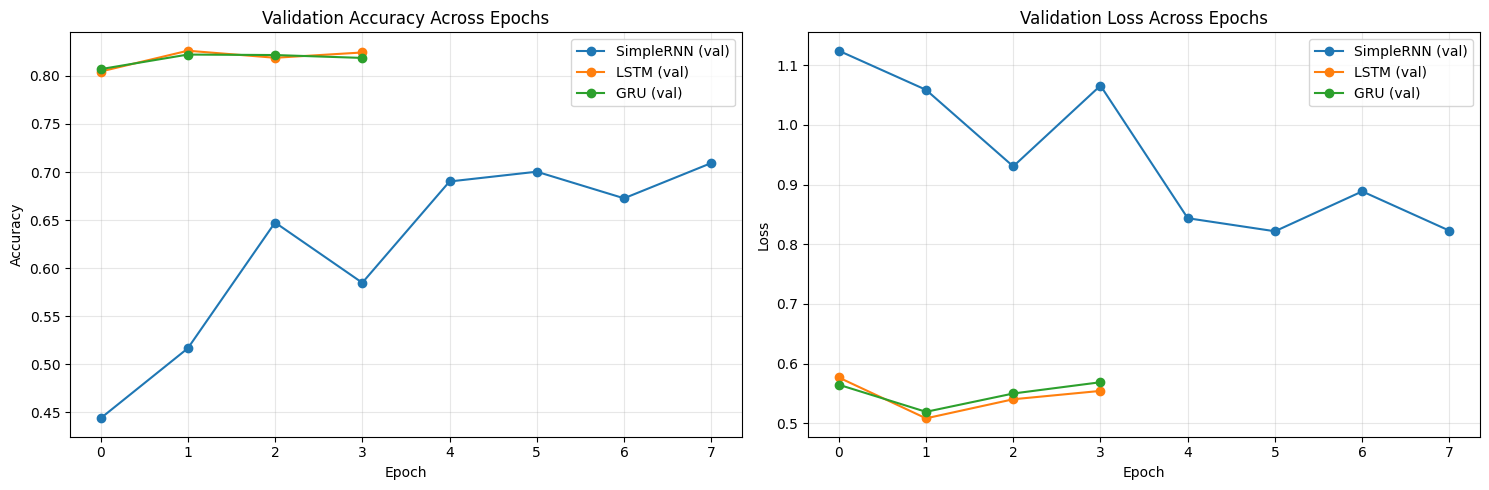

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for arch, hist in keras_histories.items():
    axes[0].plot(hist["val_accuracy"], marker="o", label=f"{arch} (val)")
    axes[1].plot(hist["val_loss"], marker="o", label=f"{arch} (val)")

axes[0].set_title("Validation Accuracy Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Validation Loss Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Fine-Tune a HuggingFace Transformer (`distilbert-base-uncased`)


In [ ]:
from datasets import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)

TRANSFORMER_MODEL_NAME = "distilbert-base-uncased"
TRANSFORMER_MAX_LEN = 256

hf_tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_MODEL_NAME)


def tokenize_batch(batch):
    return hf_tokenizer(
        batch["raw_text"],
        truncation=True,
        max_length=TRANSFORMER_MAX_LEN,
    )


train_ds = Dataset.from_pandas(train_df[["raw_text", "label_id"]].rename(columns={"label_id": "label"}))
val_ds = Dataset.from_pandas(val_df[["raw_text", "label_id"]].rename(columns={"label_id": "label"}))
test_ds = Dataset.from_pandas(test_df[["raw_text", "label_id"]].rename(columns={"label_id": "label"}))

train_ds = train_ds.map(tokenize_batch, batched=True, remove_columns=["raw_text"])
val_ds = val_ds.map(tokenize_batch, batched=True, remove_columns=["raw_text"])
test_ds = test_ds.map(tokenize_batch, batched=True, remove_columns=["raw_text"])

data_collator = DataCollatorWithPadding(tokenizer=hf_tokenizer)


class WeightedTrainer(Trainer):
    """Custom Trainer using class-weighted CrossEntropyLoss for imbalanced classes."""

    def __init__(self, class_weights_tensor, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights_tensor = class_weights_tensor

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights_tensor.to(logits.device))
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_hf_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "f1_weighted": f1_score(labels, preds, average="weighted"),
    }


hf_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

class_weights_tensor = torch.tensor(class_weights_arr, dtype=torch.float32)

training_args = TrainingArguments(
    output_dir="./transformer_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    class_weights_tensor=class_weights_tensor,
    model=hf_model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=hf_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_hf_metrics,
)

trainer.train()

# Predict on test set
test_output = trainer.predict(test_ds)
model_predictions["DistilBERT"] = np.argmax(test_output.predictions, axis=-1)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/28000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

... (5 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.491076,0.516866,0.801500,0.795924,0.803684
2,0.397221,0.503808,0.839333,0.829025,0.840124
3,0.231718,0.508625,0.840667,0.830109,0.841471


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 8. Model Evaluation & 4-Model Comparison


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),F1-Score (Macro)
0,DistilBERT,0.8537,0.8573,0.8537,0.8547,0.8425
1,GRU,0.8357,0.8406,0.8357,0.8366,0.8239
2,LSTM,0.8350,0.8411,0.8350,0.8360,0.8232
3,SimpleRNN,0.6907,0.7125,0.6907,0.6958,0.6403


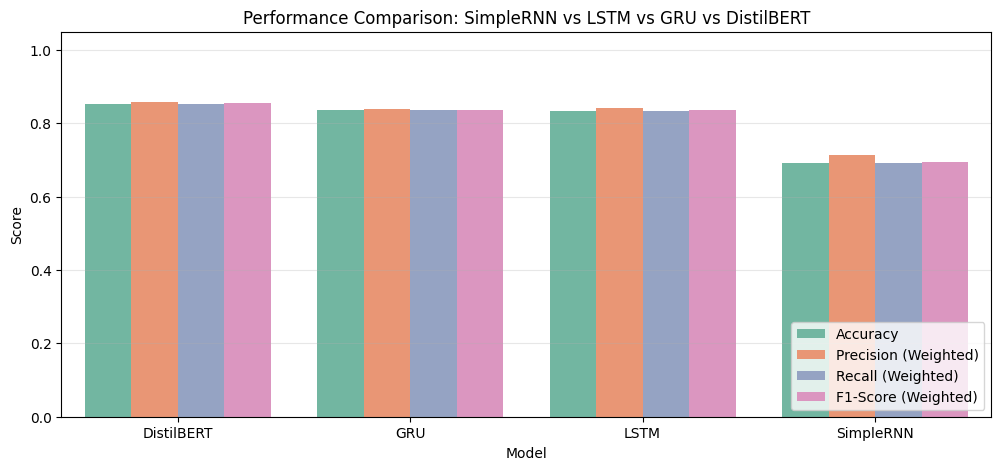

In [ ]:
results = []
for name, y_pred in model_predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1_w = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    f1_m = f1_score(y_test, y_pred, average="macro", zero_division=0)
    results.append(
        {
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision (Weighted)": round(prec, 4),
            "Recall (Weighted)": round(rec, 4),
            "F1-Score (Weighted)": round(f1_w, 4),
            "F1-Score (Macro)": round(f1_m, 4),
        }
    )

results_df = pd.DataFrame(results).sort_values(by="F1-Score (Weighted)", ascending=False).reset_index(drop=True)
display(results_df)

# Bar chart comparison
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="Set2")
plt.ylim(0, 1.05)
plt.title("Performance Comparison: SimpleRNN vs LSTM vs GRU vs DistilBERT")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()


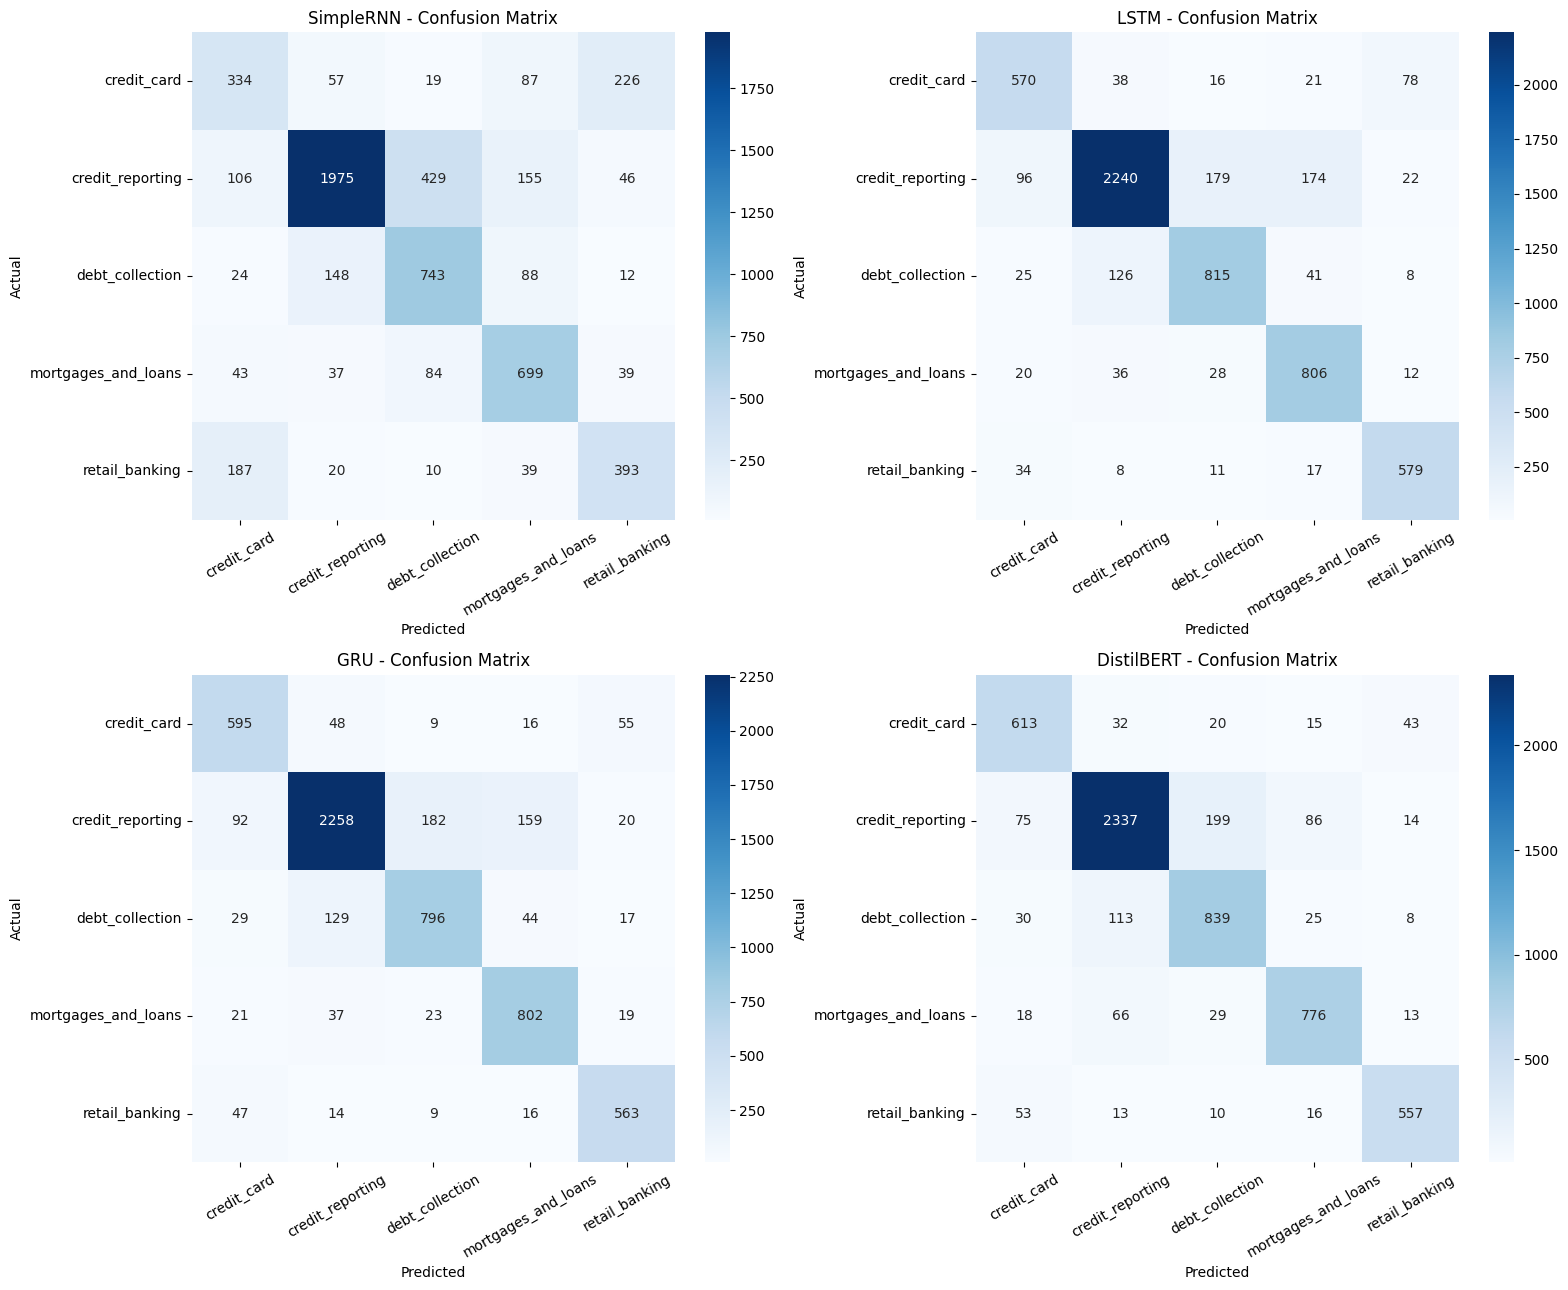


Best Performing Model: DistilBERT

Detailed Classification Report (Best Model):

                     precision    recall  f1-score   support

        credit_card       0.78      0.85      0.81       723
   credit_reporting       0.91      0.86      0.89      2711
    debt_collection       0.76      0.83      0.79      1015
mortgages_and_loans       0.85      0.86      0.85       902
     retail_banking       0.88      0.86      0.87       649

           accuracy                           0.85      6000
          macro avg       0.84      0.85      0.84      6000
       weighted avg       0.86      0.85      0.85      6000



In [ ]:
# Confusion Matrices for all 4 models
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()
class_names = [ID2LABEL[i] for i in range(NUM_CLASSES)]

for idx, (name, y_pred) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axes[idx],
    )
    axes[idx].set_title(f"{name} - Confusion Matrix")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")
    axes[idx].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print(f"\nBest Performing Model: {best_model_name}")
print("\nDetailed Classification Report (Best Model):\n")
print(classification_report(y_test, model_predictions[best_model_name], target_names=class_names))


## 9. Save the Best Model & Classify New Customer Complaints


In [ ]:
SAVE_DIR = Path("saved_model")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

if best_model_name == "DistilBERT":
    tf_dir = SAVE_DIR / "transformer"
    trainer.save_model(str(tf_dir))
    hf_tokenizer.save_pretrained(str(tf_dir))
    meta = {
        "model_type": "transformer",
        "model_name": best_model_name,
        "max_len": TRANSFORMER_MAX_LEN,
        "id2label": {str(k): v for k, v in ID2LABEL.items()},
    }
else:
    keras_models[best_model_name].save(SAVE_DIR / "keras_model.keras")
    with open(SAVE_DIR / "tokenizer.json", "w", encoding="utf-8") as f:
        f.write(keras_tokenizer.to_json())
    meta = {
        "model_type": "keras",
        "model_name": best_model_name,
        "max_len": MAX_LEN,
        "id2label": {str(k): v for k, v in ID2LABEL.items()},
    }

with open(SAVE_DIR / "model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print(f"Saved best model ({best_model_name}) to {SAVE_DIR.resolve()}")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved best model (DistilBERT) to /content/saved_model


In [ ]:
# Inference helper using the best model
def predict_complaint(text: str):
    if best_model_name == "DistilBERT":
        device = next(hf_model.parameters()).device
        hf_model.eval()
        inputs = hf_tokenizer(
            text, truncation=True, padding=True, max_length=TRANSFORMER_MAX_LEN, return_tensors="pt"
        ).to(device)
        with torch.no_grad():
            logits = hf_model(**inputs).logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    else:
        cleaned = preprocess_text(text)
        seq = keras_tokenizer.texts_to_sequences([cleaned])
        padded = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")
        probs = keras_models[best_model_name].predict(padded, verbose=0)[0]

    pred_id = int(np.argmax(probs))
    return ID2LABEL[pred_id], float(probs[pred_id]), {ID2LABEL[i]: float(probs[i]) for i in range(NUM_CLASSES)}


sample_complaints = [
    "I found an unfamiliar collection account on my credit report and the bureau refused to remove it after I disputed it.",
    "A debt collector keeps calling my workplace demanding money for a bill I already paid off.",
    "My credit card issuer charged me an unexpected annual fee and refused to waive it.",
]

for c in sample_complaints:
    cat, conf, _ = predict_complaint(c)
    print(f"Complaint : {c}\nPredicted : {cat} ({conf*100:.2f}%)\n")


Complaint : I found an unfamiliar collection account on my credit report and the bureau refused to remove it after I disputed it.
Predicted : credit_reporting (55.29%)

Complaint : A debt collector keeps calling my workplace demanding money for a bill I already paid off.
Predicted : debt_collection (97.78%)

Complaint : My credit card issuer charged me an unexpected annual fee and refused to waive it.
Predicted : credit_card (96.06%)



## 10. Interactive Gradio Deployment


In [ ]:
import shutil
from pathlib import Path
from google.colab import files

EXPORT_DIR = Path("saved_model")
results_df.to_csv(EXPORT_DIR / "model_comparison.csv", index=False)

report_text = classification_report(
    y_test,
    model_predictions[best_model_name],
    target_names=[ID2LABEL[i] for i in range(NUM_CLASSES)],
)
(EXPORT_DIR / "classification_report.txt").write_text(report_text, encoding="utf-8")

zip_path = shutil.make_archive("consumer_complaint_model_and_results", "zip", ".", "saved_model")
print("Created:", zip_path)

files.download(zip_path)

Created: /content/consumer_complaint_model_and_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>